# Regresión simbólica de KF — RUN_2 (1.356 casos)

Ejecución independiente para la hoja `RUN_2` del libro `1356_VARIACIONES_1.xlsx`. Los datos se leen y validan en bloques para hacer explícita la etapa de preparación; el ajuste simbólico utiliza después todas las filas del conjunto de entrenamiento. `EJECUCION_1` no se modifica.

Se calcula $KF=12(1-\nu^2)FCR\,h_w/(\pi^2Et_w^3)$ con $E=210000\;N/mm^2$, $\nu=0.30$, `FCR_24` en N y longitudes en mm. Entradas: `ss_hw`, `a_R`, `Do_hw`, `hw_tw`, `n_perf`. La salida y validación se guardan en `salidas_regresion_simbolica/run_2_1356/`.

In [1]:
from pathlib import Path
import os, math, tempfile, json
from itertools import product

os.environ.setdefault('JULIA_PYTHONCALL_EXE', '/usr/bin/python3.12')
import numpy as np
import pandas as pd
import sympy as sp
from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pysr import PySRRegressor

WORKBOOK = Path('1356_VARIACIONES_1.xlsx')
SHEET = 'RUN_2'
OUTPUT_DIR = Path('salidas_regresion_simbolica') / 'run_2_1356'
BLOCK_SIZE = 256
E_N_PER_MM2, NU = 210000.0, 0.30
FEATURES = ['ss_hw', 'a_R', 'Do_hw', 'hw_tw', 'n_perf']
REQUIRED = FEATURES + ['hw', 'tw', 'FCR_24']
if not WORKBOOK.is_file():
    raise FileNotFoundError(f'No se encontró el libro: {WORKBOOK.resolve()}')
print('Libro:', WORKBOOK.resolve(), '| hoja:', SHEET)

Libro: /workspaces/Regression_Symbolic_24_10/1356_VARIACIONES_1.xlsx | hoja: RUN_2


In [2]:
raw = pd.read_excel(WORKBOOK, sheet_name=SHEET)
missing = sorted(set(REQUIRED) - set(raw.columns))
if missing:
    raise ValueError(f'Faltan columnas requeridas: {missing}')
if len(raw) != 1356:
    raise ValueError(f'Se esperaban 1.356 casos en RUN_2; se encontraron {len(raw)}.')

blocks = []
for start in range(0, len(raw), BLOCK_SIZE):
    block = raw.iloc[start:start + BLOCK_SIZE].copy()
    if block[REQUIRED].isna().any().any():
        raise ValueError(f'Valores vacíos detectados en bloque de filas {start + 1} a {start + len(block)}.')
    if not np.isfinite(block[REQUIRED].to_numpy(dtype=float)).all():
        raise ValueError(f'Valores no finitos detectados en bloque de filas {start + 1} a {start + len(block)}.')
    if (block[['hw', 'tw', 'FCR_24']] <= 0).any().any():
        raise ValueError(f'Dimensiones y carga deben ser positivas (bloque {start + 1}).')
    if not np.isclose(block['n_perf'], np.round(block['n_perf'])).all():
        raise ValueError('n_perf debe ser un número entero.')
    block['n_perf'] = block['n_perf'].astype(int)
    block['KF'] = (12 * (1 - NU**2) * block['FCR_24'] * block['hw'] /
                   (math.pi**2 * E_N_PER_MM2 * block['tw']**3))
    blocks.append(block)
    print(f'Bloque {start // BLOCK_SIZE + 1}: filas {start + 1}-{start + len(block)} validadas')

df = pd.concat(blocks, ignore_index=True)
X = df[FEATURES].to_numpy(dtype=np.float64)
y = df['KF'].to_numpy(dtype=np.float64)
if not np.isfinite(y).all() or (y <= 0).any():
    raise ValueError('KF contiene valores no positivos o no finitos.')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=73)
print(f'Casos: {len(df)} | train: {len(y_train)} | test reservado: {len(y_test)}')
print(f'Rango KF: {y.min():.6g} a {y.max():.6g}')

Bloque 1: filas 1-256 validadas
Bloque 2: filas 257-512 validadas
Bloque 3: filas 513-768 validadas
Bloque 4: filas 769-1024 validadas
Bloque 5: filas 1025-1280 validadas
Bloque 6: filas 1281-1356 validadas
Casos: 1356 | train: 1084 | test reservado: 272
Rango KF: 2697.35 a 20643.5


In [3]:
configs = [
    {'name': 'balanced', 'niterations': 120, 'populations': 12, 'population_size': 32, 'maxsize': 20, 'parsimony': 0.003,
     'weight_add_node': 0.25, 'weight_insert_node': 0.20, 'weight_delete_node': 0.12, 'weight_mutate_constant': 0.18,
     'weight_mutate_operator': 0.08, 'weight_mutate_feature': 0.12},
    {'name': 'exploration', 'niterations': 160, 'populations': 16, 'population_size': 36, 'maxsize': 22, 'parsimony': 0.0005,
     'weight_add_node': 0.28, 'weight_insert_node': 0.22, 'weight_delete_node': 0.10, 'weight_mutate_constant': 0.16,
     'weight_mutate_operator': 0.10, 'weight_mutate_feature': 0.14},
    {'name': 'compacta', 'niterations': 120, 'populations': 12, 'population_size': 32, 'maxsize': 16, 'parsimony': 0.01,
     'weight_add_node': 0.20, 'weight_insert_node': 0.15, 'weight_delete_node': 0.20, 'weight_mutate_constant': 0.20,
     'weight_mutate_operator': 0.08, 'weight_mutate_feature': 0.12},
]

def fit_symbolic(config, x, target, run_id):
    params = {k: v for k, v in config.items() if k != 'name'}
    with tempfile.TemporaryDirectory(prefix=f'pysr_{run_id}_') as work_dir:
        estimator = PySRRegressor(
            **params, binary_operators=['+', '-', '*', '/'], unary_operators=['square'],
            model_selection='best', random_state=42, deterministic=True, parallelism='serial',
            timeout_in_seconds=1200, verbosity=0, progress=False,
            output_directory=work_dir, run_id=run_id,
        )
        estimator.fit(x, target)
    return estimator

def metricas(obs, pred):
    resid = pred - obs
    return {
        'MAE': float(mean_absolute_error(obs, pred)),
        'RMSE': float(np.sqrt(mean_squared_error(obs, pred))),
        'R2': float(r2_score(obs, pred)),
        'MAPE_pct': float(np.mean(np.abs(resid / obs)) * 100),
        'bias_pred_minus_obs': float(np.mean(resid)),
        'residual_std': float(np.std(resid, ddof=1)),
        'pearson_r': float(pearsonr(obs, pred).statistic) if np.std(pred) else np.nan,
        'spearman_rho': float(spearmanr(obs, pred).statistic) if np.std(pred) else np.nan,
        'positive_prediction_rate': float(np.mean(pred > 0)),
    }

comparison = []
for config in configs:
    candidate = fit_symbolic(config, X_fit, y_fit, f'run2_{config["name"]}')
    pred_val = candidate.predict(X_val)
    comparison.append({'configuration': config['name'], **metricas(y_val, pred_val),
                       'equation': str(candidate.sympy())})
    print(f"{config['name']}: RMSE={comparison[-1]['RMSE']:.4f}, MAE={comparison[-1]['MAE']:.4f}, R²={comparison[-1]['R2']:.5f}")

comparison_df = pd.DataFrame(comparison).sort_values(['RMSE', 'MAE']).reset_index(drop=True)
display(comparison_df[['configuration', 'MAE', 'RMSE', 'R2', 'MAPE_pct', 'equation']])
best_name = comparison_df.loc[0, 'configuration']
best_config = next(c for c in configs if c['name'] == best_name)
model = fit_symbolic(best_config, X_train, y_train, 'run2_test_final')
y_pred = model.predict(X_test)
equation_test = model.sympy()
test_metrics = metricas(y_test, y_pred)
rng = np.random.default_rng(42)
bootstrap_mae = np.array([np.mean(np.abs((y_pred-y_test)[rng.integers(0, len(y_test), len(y_test))])) for _ in range(2000)])
mae_ci = np.quantile(bootstrap_mae, [0.025, 0.975])
feature_symbols = {s: sp.Symbol(FEATURES[int(str(s)[1:])].upper()) for s in equation_test.free_symbols}
named_test_equation = equation_test.xreplace(feature_symbols)
print('Configuración elegida:', best_name)
print('Ecuación test:', named_test_equation)
print('Métricas holdout:', test_metrics)
print(f'IC bootstrap 95 % del MAE: [{mae_ci[0]:.4f}, {mae_ci[1]:.4f}]')

balanced: RMSE=1304.3439, MAE=966.5006, R²=0.85722


exploration: RMSE=1364.3013, MAE=1039.0225, R²=0.84379


compacta: RMSE=1328.3240, MAE=978.9315, R²=0.85192


,configuration,MAE,RMSE,R2,MAPE_pct,equation
0,balanced,966.500641,1304.343932,0.857216,12.854369,(-x4**2 + (x1 + 0.5644787)**2/(x2**4 + 0.13247...
1,compacta,978.931470,1328.323967,0.851917,13.651203,x1*(23188.63 + x2**2*(-63838.676)) - 123.67291...
2,exploration,1039.022525,1364.301280,0.843787,14.862401,((x1 - x2)/0.013276453 + 92.00593 + 6.5118427/...


Configuración elegida: balanced
Ecuación test: (-(A_R + 5.2672687)*(DO_HW**2 - 3.9046738) - 11.208642)**4
Métricas holdout: {'MAE': 1214.939079201368, 'RMSE': 1561.6370597238456, 'R2': 0.7929621232198264, 'MAPE_pct': 16.595072753581714, 'bias_pred_minus_obs': -178.4403885072945, 'residual_std': 1554.2685645374554, 'pearson_r': 0.8931727267984234, 'spearman_rho': 0.8789455235503796, 'positive_prediction_rate': 1.0}
IC bootstrap 95 % del MAE: [1100.7983, 1336.4509]


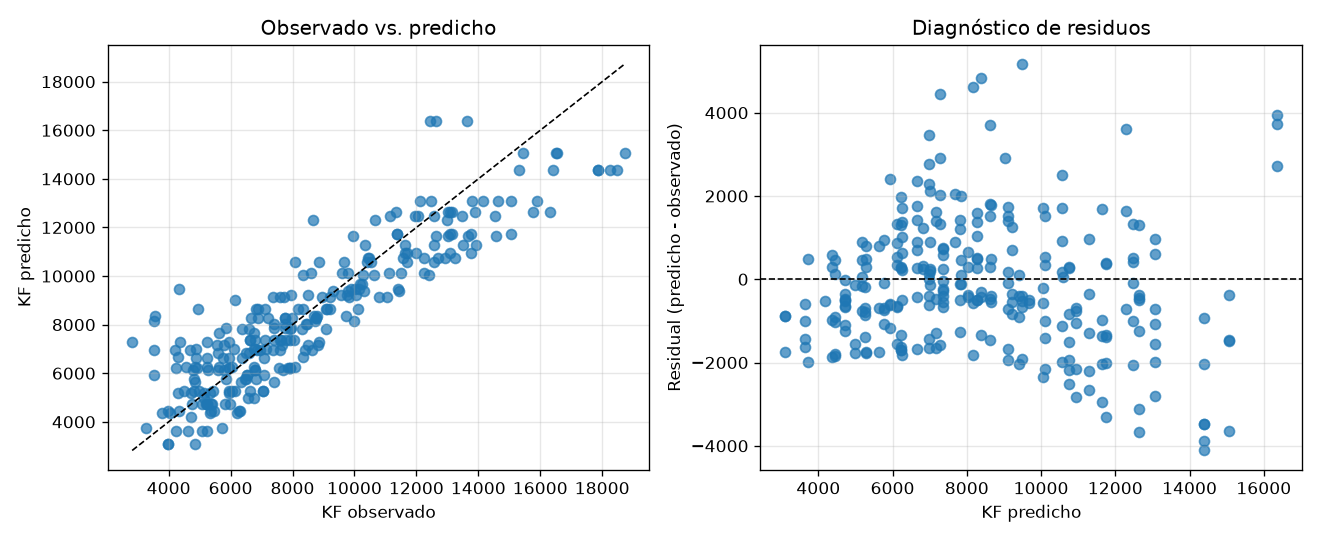

In [4]:
from io import BytesIO
import matplotlib.pyplot as plt
from IPython.display import Image, display
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y_test, y_pred, alpha=0.7)
limits = [min(float(y_test.min()), float(y_pred.min())), max(float(y_test.max()), float(y_pred.max()))]
axes[0].plot(limits, limits, 'k--', linewidth=1)
axes[0].set(xlabel='KF observado', ylabel='KF predicho', title='Observado vs. predicho')
axes[0].grid(alpha=0.3)
axes[1].scatter(y_pred, y_pred-y_test, alpha=0.7)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(xlabel='KF predicho', ylabel='Residual (predicho - observado)', title='Diagnóstico de residuos')
axes[1].grid(alpha=0.3)
fig.tight_layout()
image = BytesIO()
fig.savefig(image, format='png', dpi=120)
display(Image(data=image.getvalue()))
plt.close(fig)

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
final_model = fit_symbolic(best_config, X, y, 'run2_modelo_final_1356')
final_equation = final_model.sympy()
final_named = final_equation.xreplace({s: sp.Symbol(FEATURES[int(str(s)[1:])].upper()) for s in final_equation.free_symbols})
df_out = df.copy()
df_out['KF_predicho_modelo_final'] = final_model.predict(X)
df_out.to_csv(OUTPUT_DIR / 'predicciones_1356_casos.csv', index=False)

unique_values = [sorted(df[c].unique().tolist()) for c in FEATURES]
n_combinations = int(np.prod([len(v) for v in unique_values]))
if n_combinations > 100000:
    raise ValueError(f'Producto cartesiano de {n_combinations} combinaciones excede el límite seguro de 100.000.')
combo = pd.DataFrame(product(*unique_values), columns=FEATURES)
combo['KF_predicho'] = final_model.predict(combo[FEATURES].to_numpy(dtype=np.float64))
combo.to_csv(OUTPUT_DIR / 'predicciones_combinaciones.csv', index=False)
comparison_df.to_csv(OUTPUT_DIR / 'comparacion_configuraciones.csv', index=False)
metrics_export = test_metrics | {
    'MAE_bootstrap_95_low': float(mae_ci[0]), 'MAE_bootstrap_95_high': float(mae_ci[1]),
    'selected_configuration': best_name, 'n_train': len(y_train), 'n_test': len(y_test),
}
pd.DataFrame([metrics_export]).to_csv(OUTPUT_DIR / 'metricas_test.csv', index=False)
summary = {
    'worksheet': SHEET, 'cases': len(df), 'features': FEATURES, 'target': 'KF',
    'KF_definition': '12*(1-nu^2)*FCR_24*hw/(pi^2*E*tw^3)',
    'E_N_per_mm2': E_N_PER_MM2, 'nu': NU, 'selected_configuration': best_name,
    'test_metrics': test_metrics,
    'MAE_bootstrap_95_interval': [float(mae_ci[0]), float(mae_ci[1])],
    'test_equation_named': str(named_test_equation),
    'final_equation_sympy': str(final_equation), 'final_equation_named': str(final_named),
    'combinations_predicted': n_combinations,
}
(OUTPUT_DIR / 'expresion_y_validacion.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Resultados guardados en:', OUTPUT_DIR.resolve())
print('Ecuación final con todos los casos:', final_named)
print('Combinaciones predichas:', n_combinations)
print('Archivos: expresion_y_validacion.json, metricas_test.csv, comparacion_configuraciones.csv, predicciones_1356_casos.csv, predicciones_combinaciones.csv')

Resultados guardados en: /workspaces/Regression_Symbolic_24_10/salidas_regresion_simbolica/run_2_1356
Ecuación final con todos los casos: -HW_TW*(-A_R*(209.49496 - 566.5423*DO_HW**2) + N_PERF**2) + 6177.832
Combinaciones predichas: 2160
Archivos: expresion_y_validacion.json, metricas_test.csv, comparacion_configuraciones.csv, predicciones_1356_casos.csv, predicciones_combinaciones.csv
